*Bonus exercise of TD1:*

Let the following data correspond to greenhouse gases accumulated in the atmosphere per year (approximated and in teratonnes to simplify the calculation), and the corresponding deviation from the mean Earth temperature:

| Year | Greenhouse gases (tT) | Temperature (°C) |
|---|---:|---:|
| 2006 | 39 | 0.67 |
| 2008 | 42 | 0.69 |
| 2010 | 43 | 0.72 |
| 2012 | 45 | 0.74 |
| 2014 | 45 | 0.77 |
| 2016 | 47 | 0.80 |
| 2018 | 47 | 0.82 |
| 2020 | 49 | 0.85 |

First I extracted the following data from an Excel sheet so that i could work on them with python

In [7]:
import pandas as pd

df = pd.read_excel("TD1-bonus.xlsx")
df= df.dropna() #remove null values from sheet
df.info()  #prints the info (also good to check)

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Year                        8 non-null      int64  
 1   Greenhouse gases (tT)       8 non-null      int64  
 2   Temperature deviation (°C)  8 non-null      float64
dtypes: float64(1), int64(2)
memory usage: 324.0 bytes


**1. We are trying to explain the deviation from the mean temperature on earth as a function of
the quantity of the greenhouse gases accumulated in the atmosphere. What is the observed
variable and the latent variable ?**


The **observed variable** is the greenhouse gases accumulated in the atmosphere x. 
The **latent variable** is the temperature deviation y.

**2. Compute the mean and the variance of both variables.**

I'll extract the data as year , x , and y.

In [8]:
x =df["Greenhouse gases (tT)"]
y= df["Temperature deviation (°C)"]
year =df["Year"]

Computing the mean and the variance

In [9]:
x_mean= x.mean()
y_mean= y.mean()

x_var= x.var(ddof=0)
y_var=y.var(ddof=0)

print("mean of x= ",x_mean," Var(x)= ",x_var)
print("mean of y= ",y_mean," Var(y)= ",y_var)

mean of x=  44.625  Var(x)=  8.984375
mean of y=  0.7575000000000001  Var(y)=  0.0035437499999999996


**3. Compute the equation of the line with the estimated values of the coefficient β0 and β1.**


In [10]:
cov_xy = ((x-x_mean)*(y-y_mean)).mean()

beta1= cov_xy/x_var
beta0 = y_mean-beta1*x_mean

print("beta1= ",beta1)
print("beta0= ",beta0)

beta1=  0.01923478260869565
beta0=  -0.10085217391304324


Plot the graph

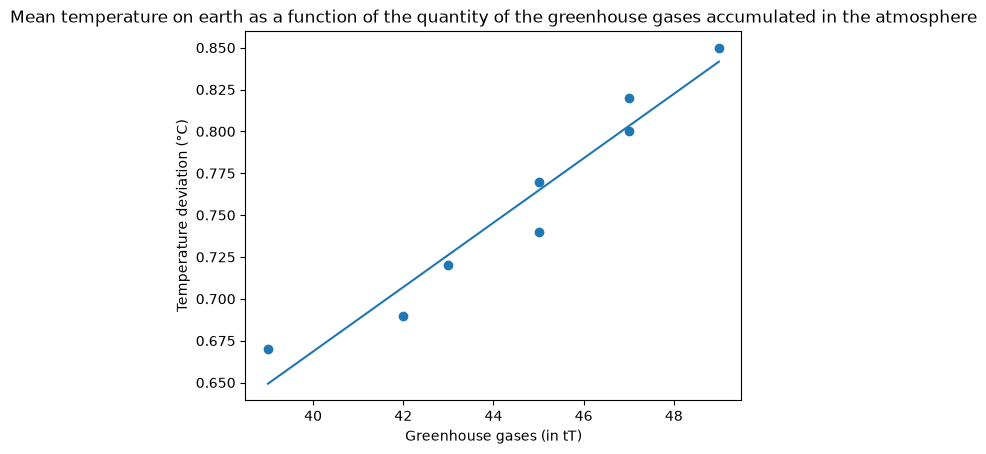

In [11]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(x,y)
x_line= np.linspace(x.min(), x.max(), 100)
y_line= beta0+beta1*x_line
plt.xlabel("Greenhouse gases (in tT)")
plt.ylabel("Temperature deviation (°C)")
plt.plot(x_line,y_line)
plt.title("Mean temperature on earth as a function of the quantity of the greenhouse gases accumulated in the atmosphere")
plt.show()